In [1]:
%matplotlib inline
import lightkurve as lk
import matplotlib.pyplot as plt
import numpy as np

c:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightkurve\prf\__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [4]:
search_ffi = lk.search_tesscut('TIC 307210830')
search_tpf=lk.search_targetpixelfile('TIC 307210830')
search_lcf=lk.search_lightcurve('TIC 307210830')


In [5]:
search_ffi

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 05,2018,TESScut,1426,TIC 307210830,0.0
1,TESS Sector 01,2018,TESScut,1426,TIC 307210830,0.0
2,TESS Sector 02,2018,TESScut,1426,TIC 307210830,0.0
3,TESS Sector 10,2019,TESScut,1426,TIC 307210830,0.0
4,TESS Sector 11,2019,TESScut,1426,TIC 307210830,0.0
5,TESS Sector 12,2019,TESScut,1426,TIC 307210830,0.0
6,TESS Sector 08,2019,TESScut,1426,TIC 307210830,0.0
7,TESS Sector 09,2019,TESScut,1426,TIC 307210830,0.0
8,TESS Sector 32,2020,TESScut,475,TIC 307210830,0.0


In [6]:
search_tpf

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 02,2018,SPOC,120,307210830,0.0
1,TESS Sector 05,2018,SPOC,120,307210830,0.0
2,TESS Sector 08,2019,SPOC,120,307210830,0.0
3,TESS Sector 09,2019,SPOC,120,307210830,0.0
4,TESS Sector 10,2019,SPOC,120,307210830,0.0
5,TESS Sector 11,2019,SPOC,120,307210830,0.0
6,TESS Sector 12,2019,SPOC,120,307210830,0.0
7,TESS Sector 28,2020,SPOC,20,307210830,0.0
8,TESS Sector 29,2020,SPOC,20,307210830,0.0


In [7]:
search_lcf

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 02,2018,SPOC,120,307210830,0.0
1,TESS Sector 05,2018,SPOC,120,307210830,0.0
2,TESS Sector 08,2019,SPOC,120,307210830,0.0
3,TESS Sector 09,2019,SPOC,120,307210830,0.0
4,TESS Sector 10,2019,SPOC,120,307210830,0.0
5,TESS Sector 11,2019,SPOC,120,307210830,0.0
6,TESS Sector 12,2019,SPOC,120,307210830,0.0
7,TESS Sector 28,2020,SPOC,20,307210830,0.0
8,TESS Sector 29,2020,SPOC,20,307210830,0.0


<Axes: title={'center': 'Target ID: TIC 307210830, Cadence: 0'}, xlabel='Pixel Column Number', ylabel='Pixel Row Number'>

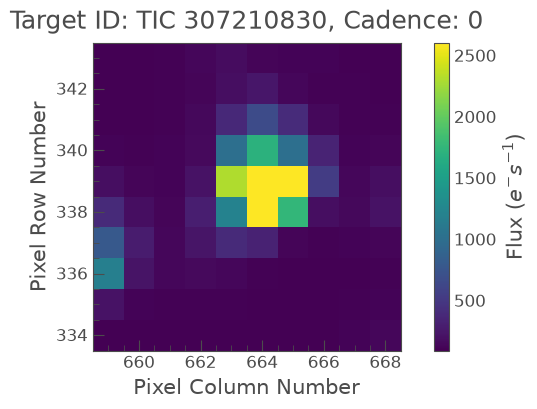

In [8]:
ffi_data=search_ffi[2].download(cutout_size=10)
ffi_data.plot()

In [9]:
target_mask=ffi_data.create_threshold_mask(threshold=15,reference_pixel='center')
n_target_pixels=target_mask.sum()
n_target_pixels

np.int64(9)

<Axes: title={'center': 'Target ID: TIC 307210830, Cadence: 0'}, xlabel='Pixel Column Number', ylabel='Pixel Row Number'>

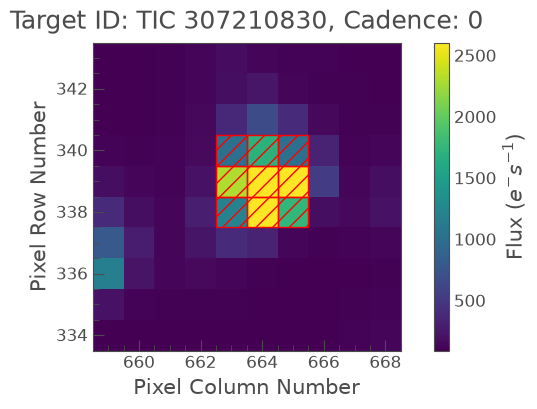

In [10]:
ffi_data.plot(aperture_mask=target_mask, mask_color='r')

<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Flux [$\\mathrm{e^{-}\\,s^{-1}}$]'>

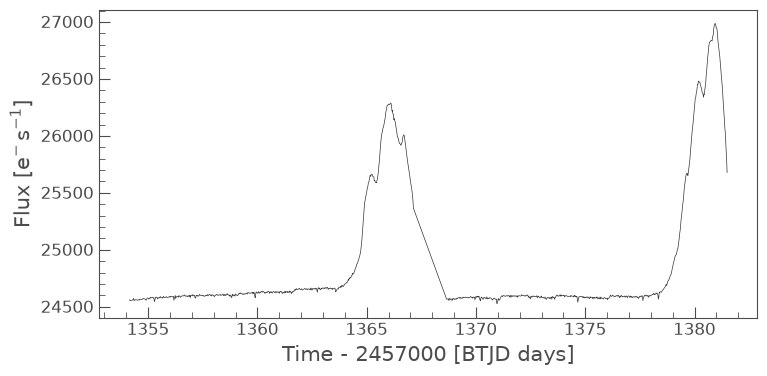

In [11]:
ffi_lc=ffi_data.to_lightcurve()
ffi_lc.plot()

<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Normalized Flux'>

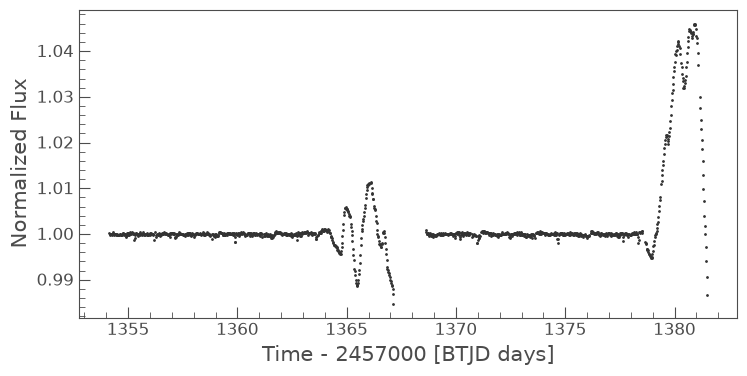

In [16]:
lc_cleaned=ffi_lc.remove_nans().remove_outliers().flatten().normalize()
lc_cleaned.scatter()